# 06 - RQ1: Fixed, global and per-label decision thresholds
Reuse `phobert_text_pw_sqrt_ep12`, the neural model selected using Midterm validation Macro-F1. No backbone training, raw dataset or Hugging Face login is needed.

Both tuning methods use the same predeclared grid: 0.05-0.90, step 0.025. Global tuning maximizes validation Macro-F1; per-label tuning maximizes each label's validation F1. Ties prefer the threshold closest to 0.5, then the smaller threshold.

**Protocol:** calibration and evaluation are separate. Thresholds are saved before test probabilities are opened. The test predictions were already inspected during the Midterm, so this is a post-hoc comparison on the existing held-out split, not a new untouched test set.

Outputs: `results/rq1/` and `reports/rq1_threshold_comparison.md`. Existing Midterm files are preserved.

In [1]:
from pathlib import Path
import sys
import pandas as pd
from IPython.display import display, Image

ROOT = Path.cwd()
if ROOT.name == 'notebooks':
    ROOT = ROOT.parent
elif ROOT.name == 'Deep-Learning':
    ROOT = ROOT / 'ati_final'
assert (ROOT / 'src' / 'analyze_thresholds.py').exists(), 'Run from ati_final or its notebooks directory'
sys.path.insert(0, str(ROOT))
from src.analyze_thresholds import calibrate, evaluate
OUT = ROOT / 'results' / 'rq1'

In [2]:
# Only validation predictions and train-derived counts are read here.
spec = calibrate(ROOT, OUT)
print('Frozen global threshold:', spec['global_threshold'])
display(pd.DataFrame({'label': spec['labels'], 'tier': [spec['tiers'][l] for l in spec['labels']],
                      'val_support': spec['validation_positive_counts'],
                      'per_label_threshold': spec['per_label_thresholds']}))

Frozen global threshold: 0.575


,label,tier,val_support,per_label_threshold
0,amusement,head,327,0.500
1,excitement,mid,91,0.525
2,joy,head,168,0.650
3,love,head,148,0.800
4,desire,mid,102,0.400
5,optimism,head,122,0.650
6,caring,head,131,0.750
7,pride,mid,87,0.625
8,admiration,mid,107,0.475
9,gratitude,mid,96,0.850


## Freeze point
`calibration.json` now contains the complete threshold specification and source hashes. Evaluation below only applies these thresholds; it does not optimize them. Do not change the grid or tie rule in response to test results.

In [3]:
results = evaluate(ROOT, OUT)
display(results[['split', 'strategy', 'macro_f1', 'micro_f1', 'hamming_loss', 'lrap', 'mAP',
                 'n_params', 'backbone_train_seconds_reported', 'additional_backbone_train_seconds']].round(4))
display(pd.read_csv(OUT / 'tables' / 'generalization_gaps.csv').round(4))

,split,strategy,macro_f1,micro_f1,hamming_loss,lrap,mAP,n_params,backbone_train_seconds_reported,additional_backbone_train_seconds
0,val,fixed,0.6030,0.6124,0.0593,0.7435,0.6197,135019804,1232.2,0.0
1,val,global,0.6077,0.6173,0.0552,0.7435,0.6197,135019804,1232.2,0.0
2,val,per_label,0.6258,0.6279,0.0543,0.7435,0.6197,135019804,1232.2,0.0
3,test,fixed,0.6082,0.6240,0.0583,0.7530,0.6304,135019804,1232.2,0.0
4,test,global,0.6125,0.6276,0.0546,0.7530,0.6304,135019804,1232.2,0.0
5,test,per_label,0.6142,0.6261,0.0552,0.7530,0.6304,135019804,1232.2,0.0


,strategy,val_macro_f1,test_macro_f1,gap_val_minus_test_macro_f1,val_micro_f1,test_micro_f1,gap_val_minus_test_micro_f1,val_hamming_loss,test_hamming_loss,gap_val_minus_test_hamming_loss
0,fixed,0.6030,0.6082,-0.0051,0.6124,0.6240,-0.0116,0.0593,0.0583,0.0010
1,global,0.6077,0.6125,-0.0048,0.6173,0.6276,-0.0103,0.0552,0.0546,0.0006
2,per_label,0.6258,0.6142,0.0116,0.6279,0.6261,0.0018,0.0543,0.0552,-0.0009


In [4]:
# Full per-label precision/recall/F1/AP are in per_label_metrics.csv.
comparison = pd.read_csv(OUT / 'tables' / 'per_label_comparison.csv')
display(comparison[['label', 'tier', 'per_label_threshold', 'test_f1_fixed', 'test_f1_global',
                    'test_f1_per_label', 'test_gain_per_label_vs_fixed', 'test_gain_per_label_vs_global']].round(4))

,label,tier,per_label_threshold,test_f1_fixed,test_f1_global,test_f1_per_label,test_gain_per_label_vs_fixed,test_gain_per_label_vs_global
0,amusement,head,0.500,0.7793,0.7769,0.7793,0.0000,0.0024
1,excitement,mid,0.525,0.5238,0.5464,0.5294,0.0056,-0.0170
2,joy,head,0.650,0.5918,0.5973,0.5687,-0.0232,-0.0287
3,love,head,0.800,0.6573,0.6806,0.7405,0.0832,0.0599
4,desire,mid,0.400,0.4410,0.4581,0.4955,0.0545,0.0374
5,optimism,head,0.650,0.7284,0.7320,0.7500,0.0216,0.0180
6,caring,head,0.750,0.6121,0.6441,0.6774,0.0653,0.0334
7,pride,mid,0.625,0.7250,0.7226,0.6933,-0.0317,-0.0292
8,admiration,mid,0.475,0.5812,0.5752,0.5714,-0.0098,-0.0038
9,gratitude,mid,0.850,0.8170,0.8158,0.8358,0.0188,0.0200


In [5]:
for name in ['tier_metrics', 'cardinality_metrics']:
    table = pd.read_csv(OUT / 'tables' / f'{name}.csv')
    display(table[table.split == 'test'].round(4))
# Cardinality is computed from unique positive multi-hot labels.
# Groups with few samples can have unstable Macro-F1; also read Micro-F1 and support.

,split,strategy,tier,n_labels,n_samples,positive_support,macro_f1,micro_f1,hamming_loss,micro_precision,micro_recall,samples_f1,mean_predicted_cardinality,mean_true_cardinality,false_positives,false_negatives,delta_macro_f1_vs_fixed,delta_micro_f1_vs_fixed,delta_hamming_loss_vs_fixed
9,test,fixed,head,10,2067,2228,0.6345,0.6510,0.0861,0.5783,0.7446,0.4795,1.3880,1.0779,1210,569,0.0000,0.0000,0.0000
10,test,fixed,mid,10,2067,1023,0.6030,0.5958,0.0451,0.5355,0.6716,0.2871,0.6207,0.4949,596,336,0.0000,0.0000,0.0000
11,test,fixed,tail,8,2067,691,0.5817,0.5781,0.0402,0.5153,0.6585,0.1726,0.4272,0.3343,428,236,0.0000,0.0000,0.0000
12,test,global,head,10,2067,2228,0.6349,0.6498,0.0818,0.6032,0.7042,0.4707,1.2583,1.0779,1032,659,0.0004,-0.0011,-0.0043
13,test,global,mid,10,2067,1023,0.6110,0.6078,0.0413,0.5738,0.6461,0.2811,0.5573,0.4949,491,362,0.0080,0.0120,-0.0038
14,test,global,tail,8,2067,691,0.5864,0.5841,0.0374,0.5459,0.6281,0.1670,0.3846,0.3343,361,257,0.0046,0.0060,-0.0028
15,test,per_label,head,10,2067,2228,0.6484,0.6599,0.0799,0.6098,0.7190,0.4809,1.2709,1.0779,1025,626,0.0139,0.0090,-0.0062
16,test,per_label,mid,10,2067,1023,0.6091,0.5877,0.0449,0.5382,0.6471,0.2773,0.5951,0.4949,568,361,0.0061,-0.0082,-0.0001
17,test,per_label,tail,8,2067,691,0.5777,0.5720,0.0372,0.5509,0.5948,0.1583,0.3609,0.3343,335,280,-0.0041,-0.0061,-0.0030


,split,strategy,cardinality,n_samples,macro_f1,micro_f1,hamming_loss,micro_precision,micro_recall,samples_f1,mean_predicted_cardinality,mean_true_cardinality,false_positives,false_negatives,delta_macro_f1_vs_fixed,delta_micro_f1_vs_fixed,delta_hamming_loss_vs_fixed
12,test,fixed,1,695,0.4581,0.5131,0.0525,0.3837,0.7741,0.5718,2.0173,1.0000,864,157,0.0000,0.0000,0.0000
13,test,fixed,2,946,0.6060,0.6357,0.0586,0.5715,0.7162,0.6416,2.5063,2.0000,1016,537,0.0000,0.0000,0.0000
14,test,fixed,3,360,0.6489,0.6922,0.0647,0.7062,0.6787,0.6862,2.8833,3.0000,305,347,0.0000,0.0000,0.0000
15,test,fixed,>=4,66,0.6329,0.7014,0.0806,0.7812,0.6364,0.6898,3.3939,4.1667,49,100,0.0000,0.0000,0.0000
16,test,global,1,695,0.4696,0.5321,0.0468,0.4137,0.7453,0.5796,1.8014,1.0000,734,177,0.0115,0.0190,-0.0057
17,test,global,2,946,0.6136,0.6396,0.0550,0.6011,0.6834,0.6386,2.2738,2.0000,858,599,0.0076,0.0039,-0.0036
18,test,global,3,360,0.6383,0.6851,0.0634,0.7323,0.6435,0.6752,2.6361,3.0000,254,385,-0.0106,-0.0071,-0.0013
19,test,global,>=4,66,0.5953,0.6709,0.0839,0.8061,0.5745,0.6578,2.9697,4.1667,38,117,-0.0376,-0.0305,0.0032
20,test,per_label,1,695,0.4835,0.5303,0.0483,0.4064,0.7626,0.5879,1.8763,1.0000,774,165,0.0254,0.0172,-0.0042
21,test,per_label,2,946,0.6164,0.6406,0.0553,0.5981,0.6897,0.6400,2.3066,2.0000,877,587,0.0104,0.0049,-0.0034


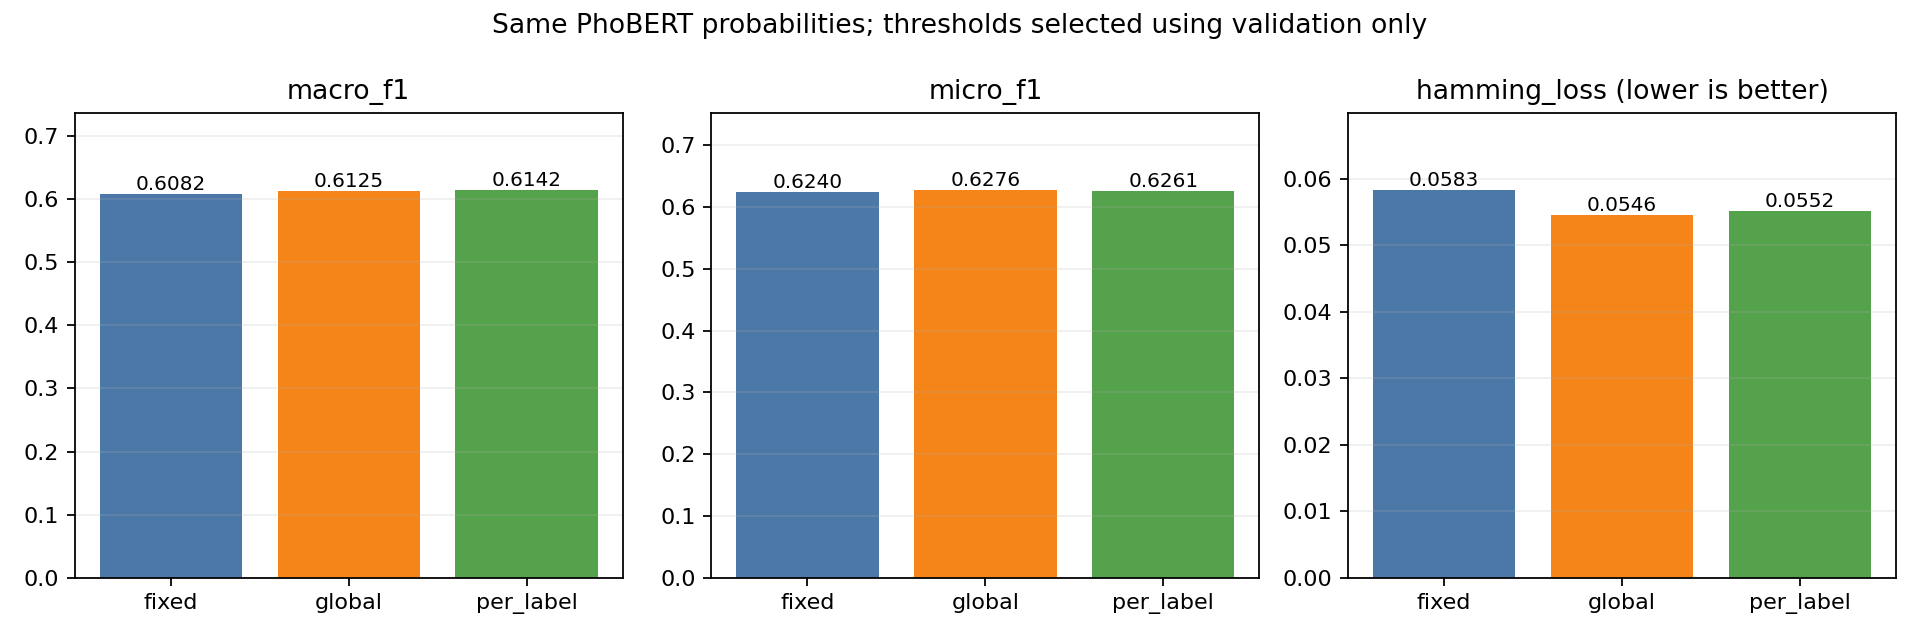

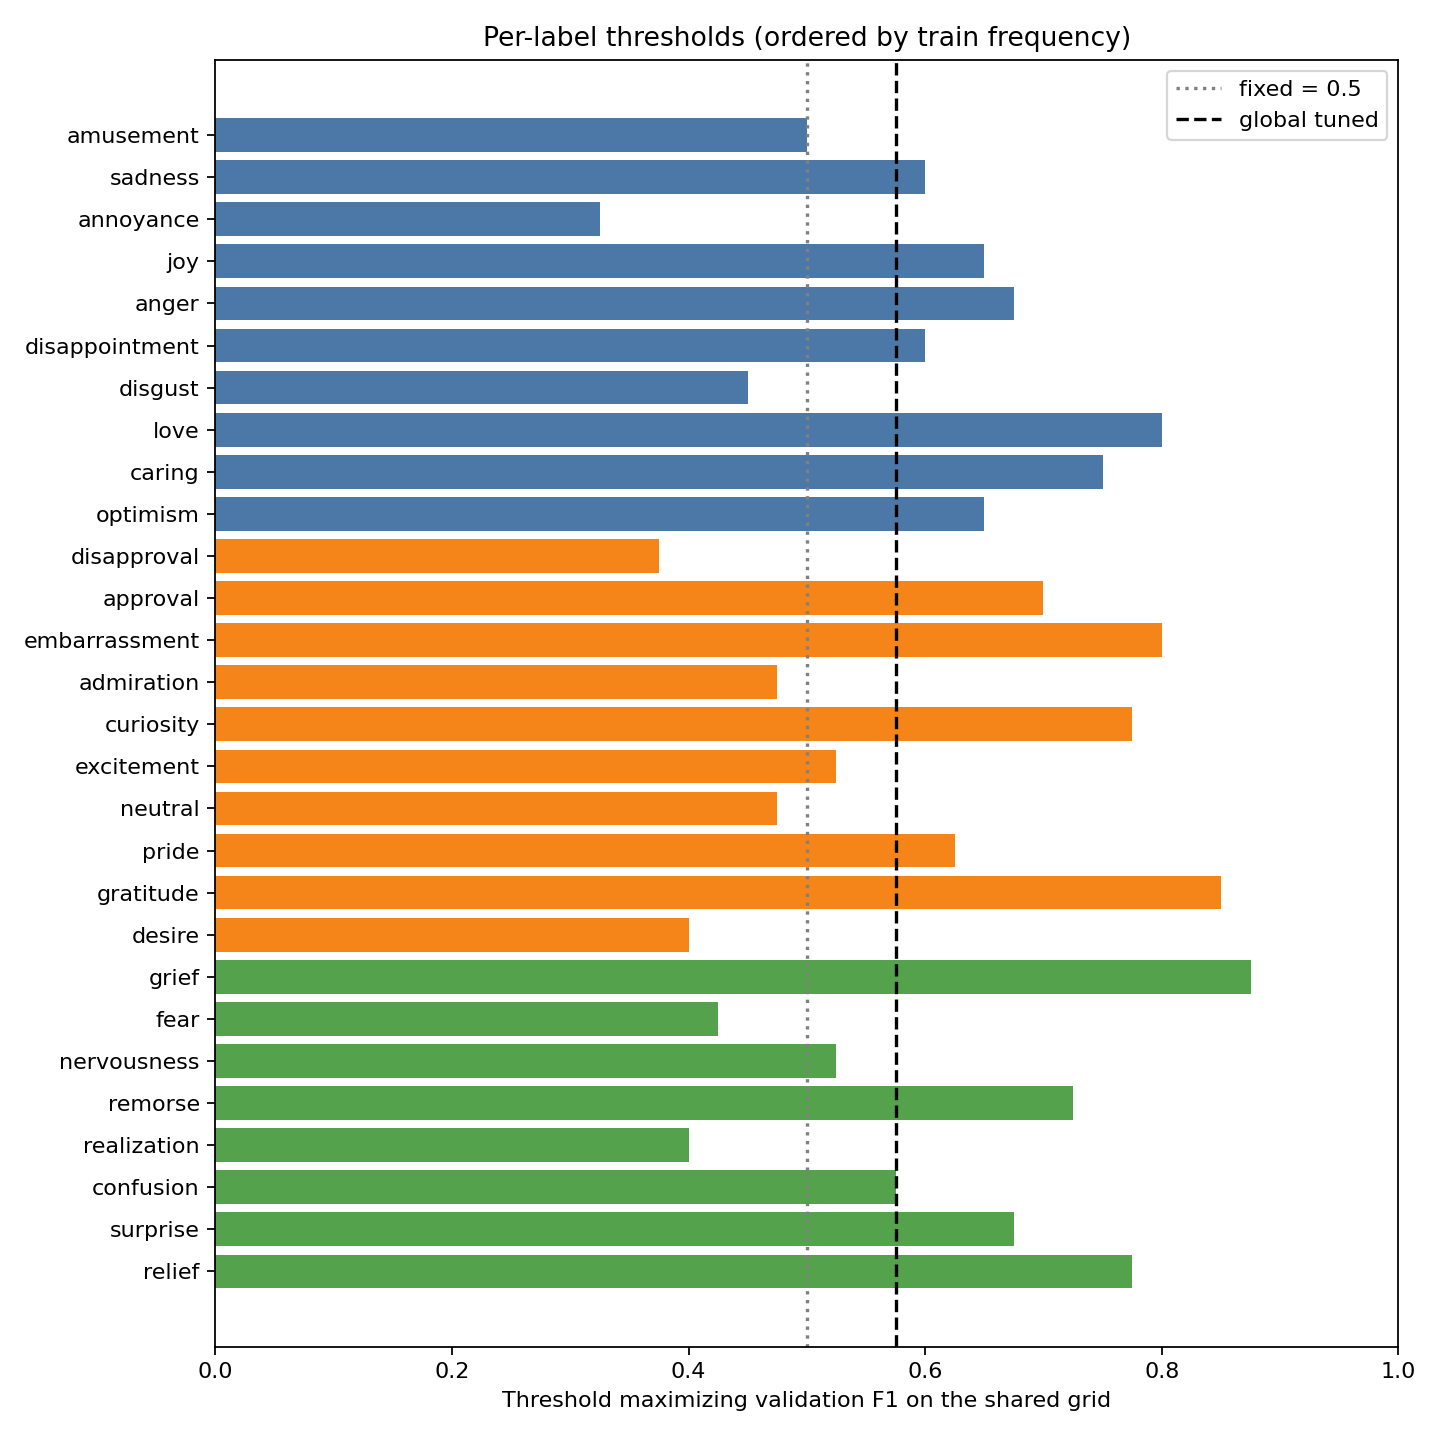

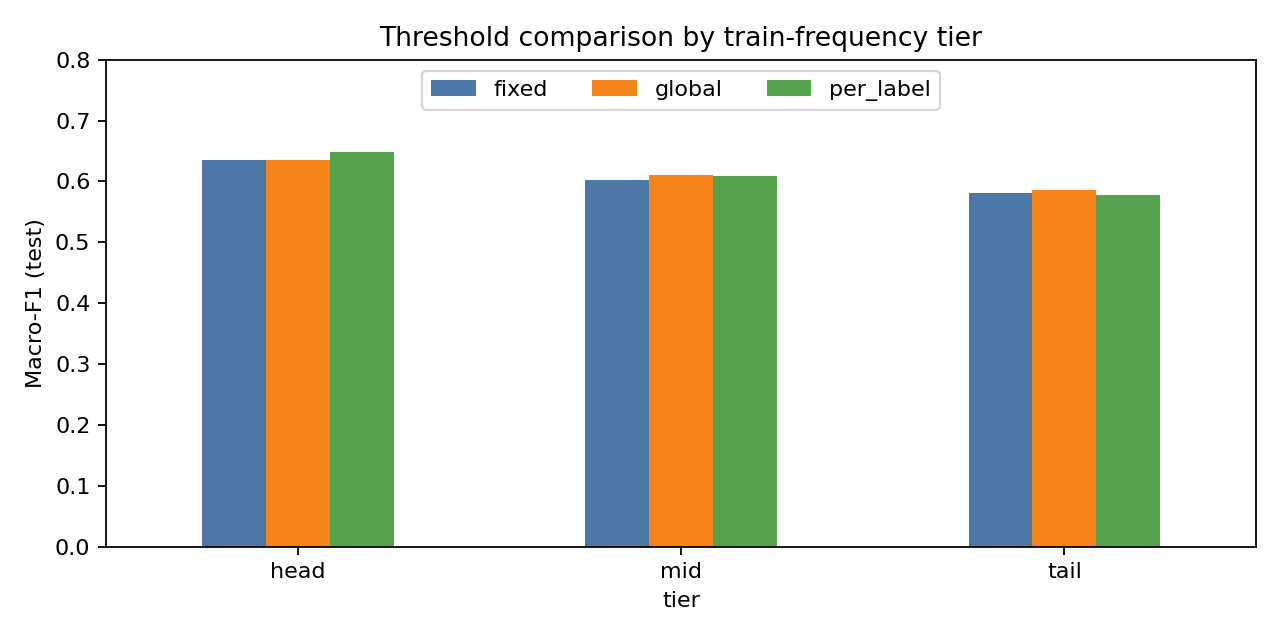

In [6]:
for name in ['strategy_metrics', 'threshold_profile', 'f1_by_tier']:
    display(Image(filename=str(OUT / 'figures' / f'{name}.png')))

## Interpretation
LRAP/mAP are unchanged because the probabilities are identical. Per-label tuning cannot lower validation Macro-F1 relative to the best global threshold on the same grid, but test performance can decrease. A larger validation-to-test gap is a warning about possible threshold overfitting; it is not a significance test.

This is one backbone and one training seed. Read the generated Vietnamese report for the measured changes and limitations. The command-line equivalent is `python -m src.analyze_thresholds`.